# 02 · Os modelos

Todos os modelos devolvem 3 probabilidades por jogo: **mandante vence**, **empate** e **visitante vence**.

| Modelo | Ideia |
|---|---|
| Baseline | Sempre a frequência histórica (~49% / 27% / 24%). Qualquer modelo tem que ganhar dele. |
| Elo + logística | Um rating por time, atualizado a cada jogo. A diferença de Elo vira probabilidade. |
| Dixon-Coles | Gols de cada time ~ Poisson(ataque × defesa do adversário × mando). Dá a probabilidade de cada placar. |
| Gradient Boosting | Elo + forma recente (pontos e gols nos últimos 5/10 jogos) + descanso + rodada. |
| Média (DC + Elo) | Média das probabilidades do Dixon-Coles e do Elo. **Modelo final.** |

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 200)

# paleta categórica validada (daltonismo) + rampa sequencial azul
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from brasileirao import load_all, build_features, DixonColes, EloLogit
from brasileirao.models import Media

df, elo = build_features(load_all())
df[["temporada", "rodada", "mandante", "visitante", "gols_m", "gols_v", "elo_m", "elo_v", "pts5_m", "pts5_v"]].tail()

,temporada,rodada,mandante,visitante,gols_m,gols_v,elo_m,elo_v,pts5_m,pts5_v
9160,2025,38,Sport,Gremio,0,4,1295.030296,1484.400063,0.0,1.4
9161,2025,38,Vitoria,Sao Paulo,1,0,1463.258139,1509.850171,1.6,1.2
9162,2025,38,Botafogo-RJ,Fortaleza,4,2,1597.727911,1493.053376,1.8,2.6
9163,2025,38,Atletico-MG,Vasco,5,0,1464.651169,1471.335749,0.4,0.6
9164,2025,38,Internacional,Bragantino,3,1,1458.358554,1465.267629,1.0,1.8


## 1. Elo

Depois de cada jogo, o vencedor ganha pontos e o perdedor perde, mais ou menos dependendo de quanto o resultado era esperado e do saldo de gols. Na virada de temporada, os ratings voltam 25% em direção à média, e clubes que sobem começam com 1430 (abaixo da média de 1500).

Ranking de Elo no fim de 2025, só com os clubes que jogaram a Série A 2025:

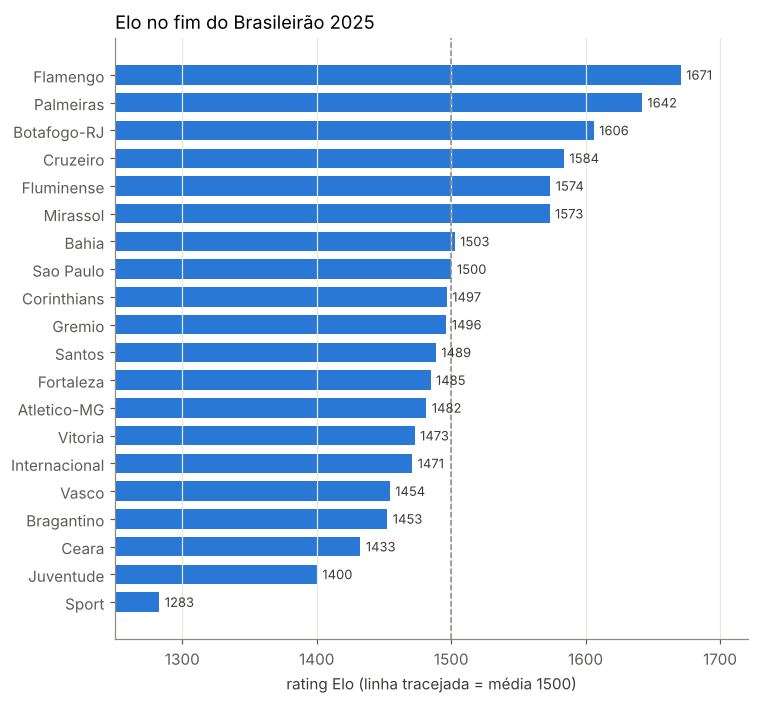

In [3]:
times_2025 = set(df[df.temporada == 2025]["mandante"])
ranking = pd.Series({t: r for t, r in elo.ratings_.items() if t in times_2025}).sort_values()
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(ranking.index, ranking.values - 1250, left=1250, color=CORES[0], height=0.7)
for y, v in enumerate(ranking.values):
    ax.text(v + 4, y, f"{v:.0f}", va="center", fontsize=8.5, color="#3b3b38")
ax.axvline(1500, color="#8a8a85", lw=1, ls="--")
ax.set_xlim(1250, ranking.max() + 50); ax.grid(axis="y", visible=False)
ax.set_title("Elo no fim do Brasileirão 2025", loc="left")
ax.set_xlabel("rating Elo (linha tracejada = média 1500)")
plt.tight_layout(); plt.savefig("../results/elo_2025.png", dpi=150); plt.show()

## 2. Dixon-Coles

Ajustado com as últimas 4 temporadas. Jogos antigos pesam menos: um jogo de 1 ano atrás vale metade de um jogo de hoje. Cada time ganha um parâmetro de **ataque** e um de **defesa**.

In [4]:
dc = DixonColes().fit(df)
params = pd.DataFrame({"ataque": dc.att_, "defesa": dc.def_}, index=list(dc.times_)).loc[sorted(times_2025)]
params["força"] = params["ataque"] + params["defesa"]
print(f"vantagem de casa: x{np.exp(dc.home_):.2f} nos gols esperados do mandante | rho = {dc.rho_:.3f}")
params.sort_values("força", ascending=False).round(3)

vantagem de casa: x1.45 nos gols esperados do mandante | rho = 0.022


,ataque,defesa,força
Flamengo,0.431,0.333,0.764
Palmeiras,0.368,0.384,0.752
Mirassol,0.351,0.240,0.591
Botafogo-RJ,0.246,0.284,0.530
Cruzeiro,0.064,0.368,0.431
Fluminense,0.049,0.241,0.290
Corinthians,0.060,0.074,0.134
Sao Paulo,0.035,0.093,0.127
Bahia,0.111,0.015,0.126
Atletico-MG,0.019,0.102,0.121


## 3. Exemplo: prevendo um jogo

O Dixon-Coles dá a probabilidade de **cada placar**. Somando a parte de baixo da diagonal, a diagonal e a parte de cima, saem as 3 probabilidades.

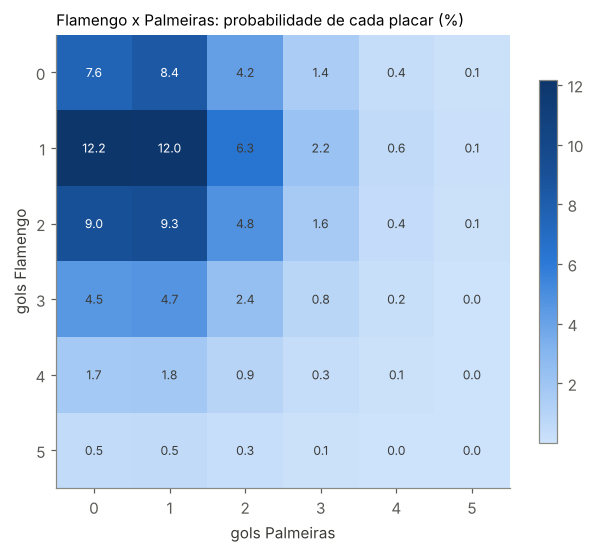

gols esperados: Flamengo 1.51 x 1.03 Palmeiras
modelo final -> Flamengo: 50.7% | empate: 25.9% | Palmeiras: 23.4%


In [5]:
mand, vis = "Flamengo", "Palmeiras"
lam, mu = dc.expected_goals(mand, vis)
M = dc.score_matrix(mand, vis)[:6, :6]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(M * 100, cmap=AZUL)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{M[i, j]*100:.1f}", ha="center", va="center", fontsize=8,
                color="white" if M[i, j] > M.max() * 0.55 else "#3b3b38")
ax.set_xlabel(f"gols {vis}"); ax.set_ylabel(f"gols {mand}")
ax.set_xticks(range(6)); ax.set_yticks(range(6)); ax.grid(False)
ax.set_title(f"{mand} x {vis}: probabilidade de cada placar (%)", loc="left", fontsize=10)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.savefig("../results/placar_exemplo.png", dpi=150); plt.show()

final = Media([DixonColes(), EloLogit()]).fit(df)
p = final.predict_proba(pd.DataFrame({"mandante": [mand], "visitante": [vis],
                                      "elo_diff": [elo.ratings_[mand] + elo.hfa - elo.ratings_[vis]]}))[0]
print(f"gols esperados: {mand} {lam:.2f} x {mu:.2f} {vis}")
print(f"modelo final -> {mand}: {p[0]:.1%} | empate: {p[1]:.1%} | {vis}: {p[2]:.1%}")

*Observação:* esse exemplo usa os dados até o fim de 2025. Pra prever jogos de 2026 o modelo precisa dos resultados de 2026 (`data/raw/jogos_2026.csv`, veja o README).